# Влияние добавления шума и изменения меток на результаты классификации MI и детекции OOD

Проводится два эксперимента: 
1. NOISE: К Обучающим и тестовым данным добавляется шум 25%, 50%, 75%, 100%. Проверяется, насколько это ухудшает результаты для классификации MI и детекции OOD. Результаты:
    * При уровне шума 100% все методы выдают результат, близкий к случайному
    * Для всех методов классификации MI (кроме VAR), результаты классификации в целом ухудшаются с увеличением уровня шума.
    * Для ShallowConvNet, ACM+TS, FBCSP результат детекции OOD в целом ухудшается с добавлением уровня шума, но эта связь выглядит менее линейной. 
    * Для log-bandpower результаты OOD детекции практически не меняются при уровнях шума 25%, 50%, 75%.
    * Для VAR результат как классификации MI, так и детекции OOD с уровнем шума 0 получился значительно хуже, чем с уровнем 25%. С дальнейшим увеличением результат ухудшается.
2. SHUFFLE: Метки left_hand, right_hand меняются местами: 25% и 50%. Аналогично, проверяем, насколько это влияет на классификацию MI и детекцию OOD. Результаты: 
    * Такое изменение влияет на результаты классификации MI, но мало влияет на результаты детекции OOD. 

Вывод: Различные проблемы в данных могут по-разному влиять на успешность классификации MI и детекции OOD. 

Датасет: BNCI2014_001

Обучение на 1 сессии, тест на второй.

Для методов выбран одинаковый классификатор shLDA (кроме ShallowConvNet) и одинаковый детектор kNN.



In [6]:
import os
import sys
from pathlib import Path
from datetime import datetime

EXPERIMENT_DIR = Path("/Users/liza/Projects/vkr/mi-ood")
os.chdir(EXPERIMENT_DIR)
sys.path.insert(0, str(EXPERIMENT_DIR))

DATA_ROOT = Path.home() / "mne_data"
os.environ["MNE_DATA"] = str(DATA_ROOT)
os.environ["MNE_DATASETS_BNCI_PATH"] = str(DATA_ROOT)
os.environ["MOABB_DOWNLOAD_PROVIDER"] = "upstream"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pipelines import mi_pipelines, ood_pipelines
from processing import *


In [7]:
experiments = ["NOISE", "SHUFFLE"]

datasets = ["BNCI2014_001"]
COMMON_CHANNELS = None

MI_METHODS = [ "FBCSP+shLDA", "ACM+TS+shLDA", "VAR+shLDA", "Log-bandpower+shLDA", "ShallowConvNet"]
OOD_METHODS = ["FBCSP+kNN", "ACM+TS+kNN","VAR+kNN", "Log-bandpower+kNN", "ShallowConvNet+kNN"]

NOISE_LEVELS = [0, 25, 50, 75, 100]
NOISE_SEED = 42
SHUFFLE_LEVELS = [0, 25, 50]
SHUFFLE_SEED = 42


In [8]:
def add_noise(data, level, noise_scale, seed):
    X, y = data
    noise = np.random.default_rng(np.random.SeedSequence(seed)).standard_normal(X.shape)
    return ((1 - level) * X + level * noise_scale * noise, y)


def shuffle_labels(data, percent, seed):
    X, y = data
    assert set(np.unique(y)) == set(HANDS)
    y_new = y.copy()
    rng = np.random.default_rng(np.random.SeedSequence(seed))
    for source, target in [("left_hand", "right_hand"), ("right_hand", "left_hand")]:
        indices = rng.permutation(np.flatnonzero(y == source))
        y_new[indices[:round(len(indices) * percent / 100)]] = target
    return X, y_new


In [9]:
for dataset in datasets:
    print(dataset)
    subjects = get_subjects(dataset)
    for subject in subjects:
        ood = ("feet",)
        clean_train, _, clean_test = load_subject_data(dataset, subject, channels=COMMON_CHANNELS, ood_classes=ood)
        X_train, y_train = clean_train
        X_test, y_test = clean_test
        noise_scale = np.sqrt(np.mean(X_train.astype(np.float64) ** 2))

        for experiment in experiments:
            levels = NOISE_LEVELS if experiment == "NOISE" else SHUFFLE_LEVELS
            for percent in levels:
                if experiment == "NOISE":
                    level = percent / 100
                    train_data = add_noise(clean_train, level, noise_scale, [NOISE_SEED, subject, 0])
                    test_data = add_noise(clean_test, level, noise_scale, [NOISE_SEED, subject, 1])
                    metadata = {"noise_level": percent, "noise_seed": NOISE_SEED}
                else:
                    train_data = shuffle_labels(clean_train, percent, [SHUFFLE_SEED, subject])
                    test_data = clean_test
                    metadata = {"shuffle_level": percent, "shuffle_seed": SHUFFLE_SEED}
                is_id = np.isin(y_test, HANDS)
                mi_test_data = (test_data[0][is_id], y_test[is_id])

                for method, pipeline in mi_pipelines.items():
                    if method not in MI_METHODS: continue
                    result = {"dataset": dataset, "subject": subject, "experiment": experiment, "experiment_type": f"mi_{percent}",
                              "method": method, **metadata}
                    if result_path(result).exists(): continue
                    result["MI_BA"], result["MI_AUROC"] = MI_metrics(train_data, mi_test_data, pipeline)
                    save_result(result)
                    print(f"[{datetime.now():%H:%M:%S}] {experiment} {dataset} s{subject:02d} {method} {percent}%: MI BA={result['MI_BA']:.3f}")

                for method, pipeline in ood_pipelines.items():
                    if method not in OOD_METHODS: continue
                    result = {"dataset": dataset, "subject": subject, "experiment": experiment, "experiment_type": f"ood_{percent}",
                              "method": method, **metadata}
                    if result_path(result).exists(): continue
                    model = train(train_data, pipeline)
                    result["OOD_AUROC"] = OOD_AUROC(test_data, model)
                    save_result(result)
                    print(f"[{datetime.now():%H:%M:%S}] {experiment} {dataset} s{subject:02d} {method} {percent}%: OOD AUROC={result['OOD_AUROC']:.3f}")


BNCI2014_001


Saved to results/NOISE.csv
NOISE: MI_BA


,dataset,method,0,25,50,75,100
0,BNCI2014_001,ACM+TS+shLDA,0.800,0.748,0.692,0.584,0.497
1,BNCI2014_001,FBCSP+shLDA,0.794,0.743,0.667,0.561,0.507
2,BNCI2014_001,Log-bandpower+shLDA,0.674,0.660,0.611,0.573,0.519
3,BNCI2014_001,ShallowConvNet,0.718,0.725,0.704,0.603,0.504
4,BNCI2014_001,VAR+shLDA,0.590,0.707,0.661,0.562,0.500


NOISE: OOD_AUROC


,dataset,method,0,25,50,75,100
0,BNCI2014_001,ACM+TS+kNN,0.663,0.694,0.652,0.574,0.512
1,BNCI2014_001,FBCSP+kNN,0.715,0.710,0.672,0.589,0.484
2,BNCI2014_001,Log-bandpower+kNN,0.556,0.555,0.563,0.560,0.514
3,BNCI2014_001,ShallowConvNet+kNN,0.679,0.674,0.644,0.574,0.507
4,BNCI2014_001,VAR+kNN,0.504,0.635,0.602,0.546,0.506


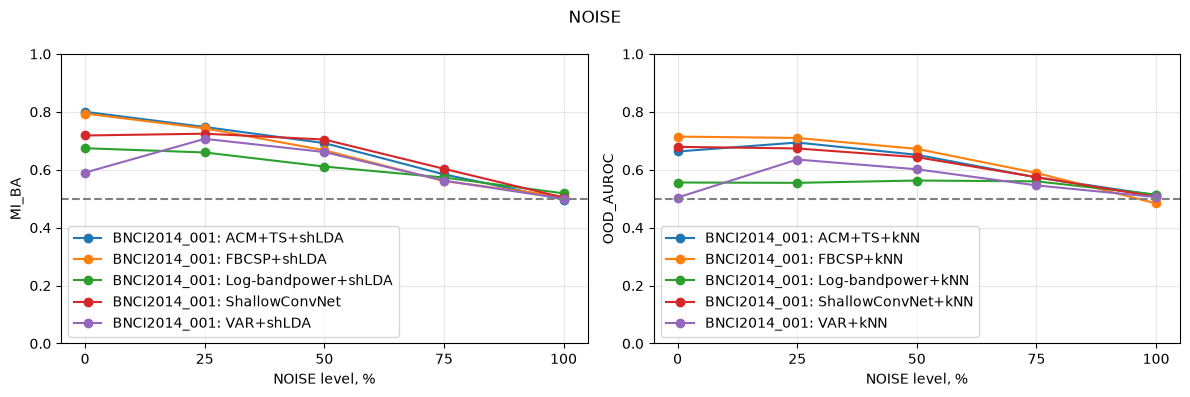

Saved to results/SHUFFLE.csv
SHUFFLE: MI_BA


,dataset,method,0,25,50
0,BNCI2014_001,ACM+TS+shLDA,0.800,0.686,0.527
1,BNCI2014_001,FBCSP+shLDA,0.794,0.677,0.512
2,BNCI2014_001,Log-bandpower+shLDA,0.674,0.609,0.510
3,BNCI2014_001,ShallowConvNet,0.718,0.592,0.506
4,BNCI2014_001,VAR+shLDA,0.590,0.555,0.493


SHUFFLE: OOD_AUROC


,dataset,method,0,25,50
0,BNCI2014_001,ACM+TS+kNN,0.663,0.663,0.663
1,BNCI2014_001,FBCSP+kNN,0.715,0.680,0.671
2,BNCI2014_001,Log-bandpower+kNN,0.556,0.556,0.556
3,BNCI2014_001,ShallowConvNet+kNN,0.679,0.659,0.635
4,BNCI2014_001,VAR+kNN,0.504,0.504,0.504


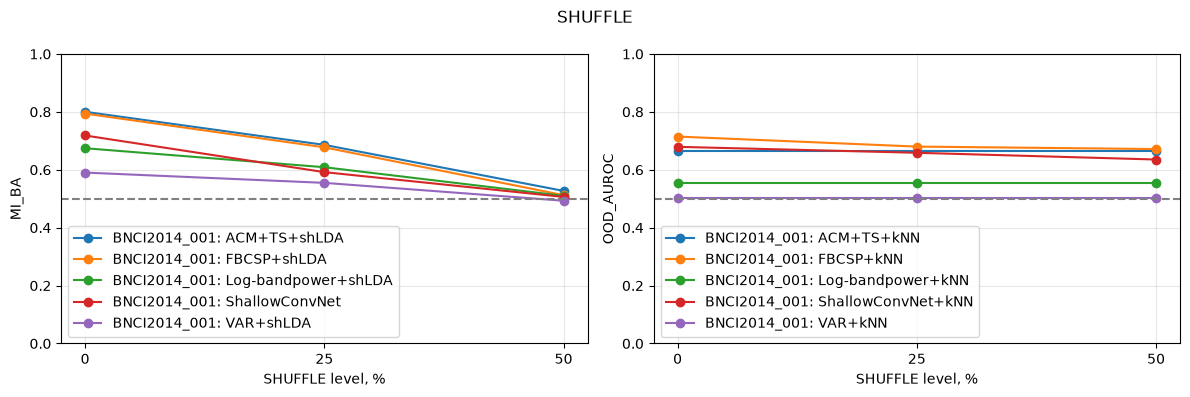

In [10]:
results_by_experiment = {}
for experiment in experiments:
    levels = NOISE_LEVELS if experiment == "NOISE" else SHUFFLE_LEVELS
    level_column = "noise_level" if experiment == "NOISE" else "shuffle_level"
    create_exp_file(experiment)
    results = pd.read_csv(Path("results") / f"{experiment}.csv")
    results_by_experiment[experiment] = results
    #display(results)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    fig.suptitle(experiment)
    for ax, task, metric in zip(axes, ["mi_", "ood_"], ["MI_BA", "OOD_AUROC"]):
        data = results[results["experiment_type"].str.startswith(task)]
        summary = data.groupby(["dataset", "method", level_column])[metric].agg(["mean", "count"]).reset_index()
        print(f"{experiment}: {metric}")
        display(summary.pivot(index=["dataset", "method"], columns=level_column, values="mean")
        .reindex(columns=levels).reset_index().rename_axis(columns=None).round(3))
        for (dataset, method), group in summary.groupby(["dataset", "method"]):
            group = group.sort_values(level_column)
            ax.plot(group[level_column], group["mean"], marker="o", label=f"{dataset}: {method}")
        ax.axhline(0.5, color="gray", linestyle="--")
        ax.set(xlabel=f"{experiment} level, %", ylabel=metric, ylim=(0, 1))
        ax.set_xticks(levels)
        ax.grid(alpha=0.3)
        ax.legend()
    plt.tight_layout()
    plt.show()
